In [1]:

from pathlib import Path
import pandas as pd
import re

root = Path("/kaggle/input")
files = list(root.rglob("*.csv"))

print("Total CSV files:", len(files))

for cutter in [1, 4, 6]:
    sensor_files = [
        p for p in files
        if re.fullmatch(
            rf"c_{cutter}_\d{{3}}\.csv",
            p.name.lower()
        )
    ]

    wear_files = [
        p for p in files
        if p.name.lower() == f"c{cutter}_wear.csv"
    ]

    print(f"\nCUTTER C{cutter}")
    print("Sensor files:", len(sensor_files))
    print("Wear files:", len(wear_files))

    if wear_files:
        wear = pd.read_csv(wear_files[0])
        print("Wear rows:", len(wear))
        print("Wear columns:", wear.columns.tolist())
        print(wear.head(3).to_string(index=False))

print("\nExample sensor file:")
example = next(
    (p for p in files if p.name.lower() == "c_1_001.csv"),
    None
)

if example:
    print("Path:", example)
    print(pd.read_csv(example, header=None, nrows=5))
else:
    print("C1 example file not found")

Total CSV files: 948

CUTTER C1
Sensor files: 315
Wear files: 1
Wear rows: 315
Wear columns: ['cut', 'flute_1', 'flute_2', 'flute_3']
 cut    flute_1    flute_2    flute_3
   1  32.317114  48.892617  37.720825
   2  37.914879  49.570815  37.720825
   3  43.087910  50.302867  37.720825

CUTTER C4
Sensor files: 315
Wear files: 1
Wear rows: 315
Wear columns: ['cut', 'flute_1', 'flute_2', 'flute_3']
 cut    flute_1    flute_2    flute_3
   1  31.416355  19.483692  21.748063
   2  34.892770  23.473047  24.925960
   3  38.102847  27.172868  27.898659

CUTTER C6
Sensor files: 315
Wear files: 1
Wear rows: 315
Wear columns: ['cut', 'flute_1', 'flute_2', 'flute_3']
 cut    flute_1    flute_2    flute_3
   1  62.788648   9.896641  14.620908
   2  64.136043  19.793281  29.241817
   3  65.365273  29.689922  43.862725

Example sensor file:
Path: /kaggle/input/c_1_001.csv
       0      1      2      3      4      5      6
0  0.704 -0.387 -1.084  0.018  0.031  0.027 -0.004
1  0.772 -0.573 -1.153 -0.05


Cutter C1
Minimum wear: 48.89
Maximum wear: 172.69
Mean wear: 113.91

Cutter C4
Minimum wear: 31.42
Maximum wear: 210.92
Mean wear: 106.4

Cutter C6
Minimum wear: 62.79
Maximum wear: 234.72
Mean wear: 139.76


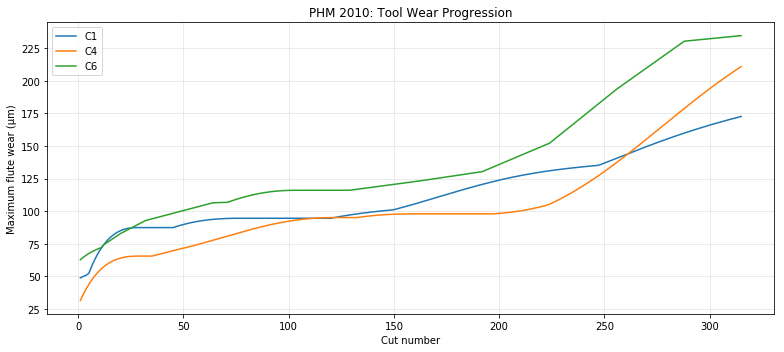

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("/kaggle/input")

wear_data = {}

for cutter in [1, 4, 6]:
    path = next(root.rglob(f"c{cutter}_wear.csv"))
    df = pd.read_csv(path)

    assert df["cut"].is_unique
    assert set(df["cut"]) == set(range(1, 316))
    assert not df.isna().any().any()

    df["wear_max"] = df[
        ["flute_1", "flute_2", "flute_3"]
    ].max(axis=1)

    wear_data[cutter] = df

    print(f"\nCutter C{cutter}")
    print("Minimum wear:", round(df["wear_max"].min(), 2))
    print("Maximum wear:", round(df["wear_max"].max(), 2))
    print("Mean wear:", round(df["wear_max"].mean(), 2))

plt.figure(figsize=(11, 5))

for cutter, df in wear_data.items():
    plt.plot(
        df["cut"],
        df["wear_max"],
        label=f"C{cutter}"
    )

plt.xlabel("Cut number")
plt.ylabel("Maximum flute wear (µm)")
plt.title("PHM 2010: Tool Wear Progression")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

FILE: c_1_001.csv
Shape: (127399, 7)
Number of sensor samples: 127399
Number of channels: 7
Missing values: 0
Infinite values: 0

First five rows:
      Fx     Fy     Fz     Vx     Vy     Vz  AE_RMS
0  0.704 -0.387 -1.084  0.018  0.031  0.027  -0.004
1  0.772 -0.573 -1.153 -0.056 -0.057 -0.058  -0.004
2  0.828 -0.673 -1.242  0.037  0.019  0.031  -0.004
3  0.866 -0.601 -1.311 -0.028 -0.027 -0.022  -0.004
4  0.910 -0.377 -1.341 -0.050 -0.049 -0.058  -0.004

Signal statistics:
                Fx           Fy           Fz           Vx           Vy  \
count  127399.0000  127399.0000  127399.0000  127399.0000  127399.0000   
mean        0.4009       0.6295       0.7051       0.0093       0.0136   
std         0.8425       1.6359       1.1275       0.0763       0.0763   
min        -2.5010     -12.0510      -3.2430      -0.3160      -0.3170   
25%        -0.1980      -0.3420      -0.0670      -0.0410      -0.0370   
50%         0.3770       0.6410       0.7080       0.0090       0.0140   
75%

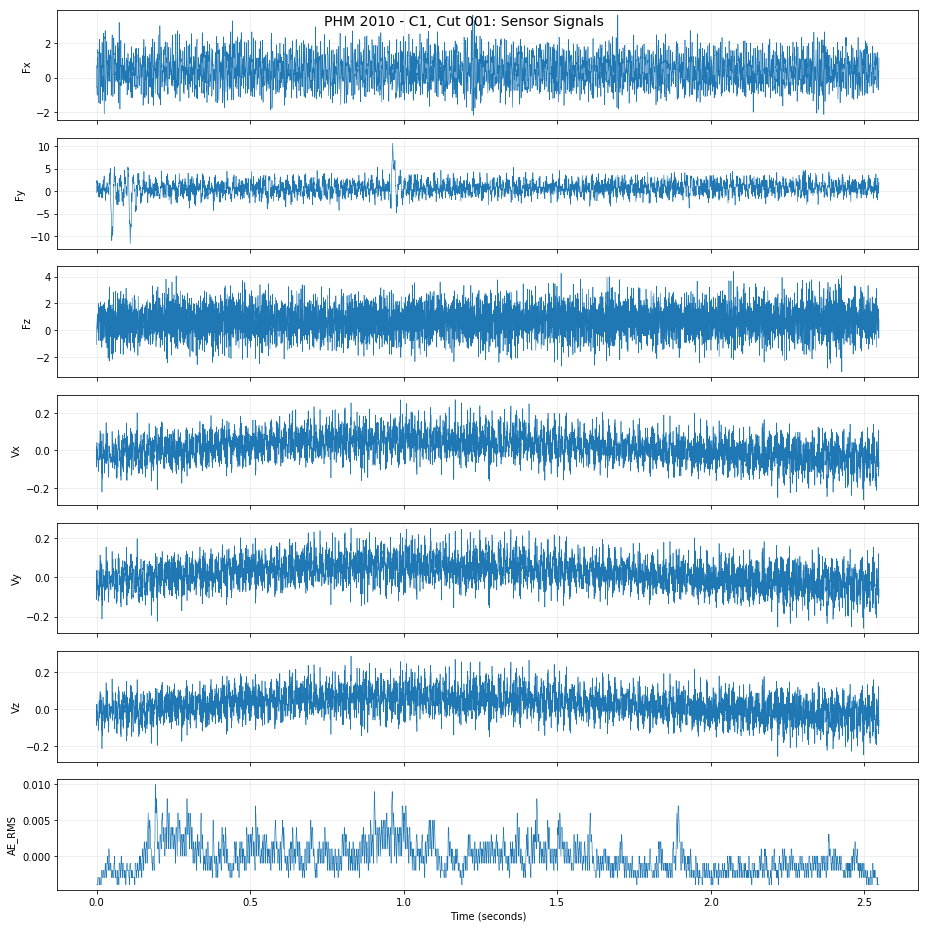

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

root = Path("/kaggle/input")

channels = [
    "Fx", "Fy", "Fz",
    "Vx", "Vy", "Vz", "AE_RMS"
]

# Inspect the first cut of cutter C1
matches = list(root.rglob("c_1_001.csv"))
assert len(matches) == 1, f"Expected one file, found {len(matches)}"

file_path = matches[0]

df = pd.read_csv(
    file_path,
    header=None,
    names=channels,
    dtype=np.float32
)

print("FILE:", file_path.name)
print("Shape:", df.shape)
print("Number of sensor samples:", len(df))
print("Number of channels:", df.shape[1])
print("Missing values:", int(df.isna().sum().sum()))
print("Infinite values:", int(np.isinf(df.to_numpy()).sum()))

print("\nFirst five rows:")
print(df.head())

print("\nSignal statistics:")
print(df.describe().round(4))

# Downsample only for plotting
step = max(1, len(df) // 5000)
sampled = df.iloc[::step]

fig, axes = plt.subplots(
    7, 1,
    figsize=(13, 13),
    sharex=True
)

for i, channel in enumerate(channels):
    axes[i].plot(
        sampled.index / 50000,
        sampled[channel],
        linewidth=0.6
    )
    axes[i].set_ylabel(channel)
    axes[i].grid(alpha=0.25)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle(
    "PHM 2010 - C1, Cut 001: Sensor Signals",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [4]:

from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from scipy.signal import periodogram
import time

ROOT = Path("/kaggle/input")
OUTPUT = Path("/kaggle/working/phm_features.csv")

CHANNELS = ["Fx", "Fy", "Fz", "Vx", "Vy", "Vz", "AE_RMS"]
CUTTERS = [1, 4, 6]
FS = 50000

def extract_features(path):
    data = pd.read_csv(
        path, header=None, dtype=np.float32
    ).values

    if data.shape[1] != 7:
        raise ValueError("Invalid channel count: " + str(path))
    if not np.isfinite(data).all():
        raise ValueError("Invalid signal values: " + str(path))

    n = len(data)
    data = data[int(n*0.10):int(n*0.90)]

    if len(data) < 100:
        raise ValueError("Too few samples: " + str(path))

    features = {}

    for j, channel in enumerate(CHANNELS):
        x = data[:, j].astype(np.float64)

        features[channel + "_mean"] = np.mean(x)
        features[channel + "_std"] = np.std(x)
        features[channel + "_rms"] = np.sqrt(np.mean(x**2))
        features[channel + "_min"] = np.min(x)
        features[channel + "_max"] = np.max(x)
        features[channel + "_ptp"] = np.ptp(x)
        features[channel + "_skew"] = skew(x)
        features[channel + "_kurtosis"] = kurtosis(x)

        freq, psd = periodogram(x, fs=FS)
        dfreq = freq[1] - freq[0]

        bands = [
            (0, 1000),
            (1000, 5000),
            (5000, 10000),
            (10000, 25000)
        ]

        for low, high in bands:
            mask = (freq >= low) & (freq < high)
            energy = np.sum(psd[mask]) * dfreq
            name = "{}_energy_{}_{}".format(channel, low, high)
            features[name] = energy

    return features

all_csv = list(ROOT.rglob("*.csv"))
rows = []
start_time = time.time()

for cutter in CUTTERS:
    wear_files = [
        p for p in all_csv
        if p.name.lower() == "c{}_wear.csv".format(cutter)
    ]

    assert len(wear_files) == 1

    wear = pd.read_csv(wear_files[0])
    assert len(wear) == 315
    assert wear["cut"].is_unique
    assert set(wear["cut"]) == set(range(1, 316))

    wear = wear.set_index("cut")
    wear["wear_max"] = wear[
        ["flute_1", "flute_2", "flute_3"]
    ].max(axis=1)

    sensor_paths = {}

    for p in all_csv:
        prefix = "c_{}_".format(cutter)
        name = p.name.lower()

        if name.startswith(prefix) and name.endswith(".csv"):
            cut_text = name[len(prefix):-4]

            if cut_text.isdigit():
                cut = int(cut_text)
                if cut in sensor_paths:
                    raise ValueError("Duplicate sensor cut")
                sensor_paths[cut] = p

    assert set(sensor_paths) == set(range(1, 316))

    print("Processing C{}...".format(cutter), flush=True)

    for cut in sorted(sensor_paths):
        features = extract_features(sensor_paths[cut])
        features["cutter"] = cutter
        features["cut"] = cut
        features["wear_max"] = wear.loc[cut, "wear_max"]

        rows.append(features)

        if cut % 50 == 0:
            print("Completed {}/315".format(cut), flush=True)

    pd.DataFrame(rows).to_csv(OUTPUT, index=False)

features_df = pd.DataFrame(rows)

assert features_df.shape == (945, 87)
assert np.isfinite(
    features_df.select_dtypes(include=[np.number]).values
).all()

features_df.to_csv(OUTPUT, index=False)

print("\nPREPROCESSING COMPLETE")
print("Dataset shape:", features_df.shape)
print("Features:", features_df.shape[1] - 3)
print("Saved to:", OUTPUT)
print("Elapsed minutes:",
      round((time.time()-start_time)/60, 2))


Processing C1...
Completed 50/315
Completed 100/315
Completed 150/315
Completed 200/315
Completed 250/315
Completed 300/315
Processing C4...
Completed 50/315
Completed 100/315
Completed 150/315
Completed 200/315
Completed 250/315
Completed 300/315
Processing C6...
Completed 50/315
Completed 100/315
Completed 150/315
Completed 200/315
Completed 250/315
Completed 300/315

PREPROCESSING COMPLETE
Dataset shape: (945, 87)
Features: 84
Saved to: /kaggle/working/phm_features.csv
Elapsed minutes: 8.23


In [5]:

from pathlib import Path
import pandas as pd
import numpy as np

file = Path("/kaggle/working/phm_features.csv")

assert file.exists(), "Feature file not found!"

df = pd.read_csv(file)

print("Dataset shape:", df.shape)
print("\nRows per cutter:")
print(df.groupby("cutter").size())

print("\nMissing values:", df.isna().sum().sum())
print("Infinite values:",
      np.isinf(df.select_dtypes(include=[np.number]).values).sum())
print("Duplicate cutter/cut pairs:",
      df.duplicated(["cutter", "cut"]).sum())


Dataset shape: (945, 87)

Rows per cutter:
cutter
1    315
4    315
6    315
dtype: int64

Missing values: 0
Infinite values: 0
Duplicate cutter/cut pairs: 0


In [6]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = pd.read_csv("/kaggle/working/phm_features.csv")

# Protocol V2: 15 blocks, 21 cuts per block
df["block"] = ((df["cut"] - 1) // 21) + 1

train_blocks = {1, 3, 5, 6, 7, 9, 10, 11, 13, 15}
val_blocks = {4, 12}
cal_blocks = {2, 8, 14}

feature_cols = [
    c for c in df.columns
    if c not in {"cutter", "cut", "wear_max", "block"}
]

assert len(feature_cols) == 84

results = []
predictions = []

for held_out in [1, 4, 6]:
    source = df[df["cutter"] != held_out]
    train = source[source["block"].isin(train_blocks)]
    val = source[source["block"].isin(val_blocks)]
    cal = source[source["block"].isin(cal_blocks)]
    test = df[df["cutter"] == held_out].sort_values("cut")

    assert (len(train), len(val), len(cal), len(test)) == (
        420, 84, 126, 315
    )

    model = RandomForestRegressor(
        n_estimators=300,
        max_features="sqrt",
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    )

    model.fit(train[feature_cols], train["wear_max"])
    pred = model.predict(test[feature_cols])

    mae = mean_absolute_error(test["wear_max"], pred)
    rmse = np.sqrt(
        mean_squared_error(test["wear_max"], pred)
    )

    results.append({
        "cutter": held_out,
        "MAE": mae,
        "RMSE": rmse
    })

    predictions.append(pd.DataFrame({
        "cutter": held_out,
        "cut": test["cut"].to_numpy(),
        "actual": test["wear_max"].to_numpy(),
        "predicted": pred
    }))

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))
print("Macro MAE:", round(results_df["MAE"].mean(), 3))
print("Macro RMSE:", round(results_df["RMSE"].mean(), 3))

pd.concat(predictions, ignore_index=True).to_csv(
    "/kaggle/working/rf_protocol_v2_predictions.csv",
    index=False
)


 cutter        MAE       RMSE
      1  10.750650  13.102407
      4  13.831810  16.981797
      6  18.649709  26.848574
Macro MAE: 14.411
Macro RMSE: 18.978
